# Beam-state test: Python vs MATLAB

Compare the **saved outputs** of the two independent initializations.

1. Run `beam_state_test.ipynb` to export inputs and Python results.
2. Run all sections of `beam_state_test.mlx` to export MATLAB results.
3. **Restart Kernel and Run All** here.

This notebook only reads result files. It does not initialize a beam, start MATLAB, or overwrite outputs. Case labels must match, but they are not input fingerprints: rerun both producers after any input change.


In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import Markdown, display

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "3.beam_state_test"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})


## 1. Load both result files

Keep stored matrix dimensions and complex values. File timestamps help identify stale results but cannot prove input identity.


In [2]:
python_file = test_directory / "python_results.mat"
matlab_file = test_directory / "matlab_results.mat"
for result_file in (python_file, matlab_file):
    if not result_file.is_file():
        raise FileNotFoundError(f"Missing {result_file}. Run both beam-state tests first.")
    modified = datetime.fromtimestamp(result_file.stat().st_mtime)
    print(f"{result_file.name}: {result_file}")
    print(f"  Last modified (local time): {modified:%Y-%m-%d %H:%M:%S}")

python_results = loadmat(python_file)
matlab_results = loadmat(matlab_file)


python_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\3.beam_state_test\python_results.mat
  Last modified (local time): 2026-10-15 16:01:01
matlab_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\3.beam_state_test\matlab_results.mat
  Last modified (local time): 2026-10-15 16:02:35


## 2. Comparison rules

Check all **19 calculated quantities**, plus exact `Nt/Ns` metadata and the case label.

- `Iz` and `QQ` must have shape `(number of grid nodes, Ns)`. Never flatten these matrices, including when `Ns = 1`.
- Only declared vectors may ignore row/column orientation. Sample vectors have `Nt` entries; longitudinal vectors have one entry per grid node.
- Compare **complex differences**, not just magnitudes: phase and sign must agree.
- Floating-point values pass at every entry when `abs(Python - MATLAB) <= atol + rtol * abs(MATLAB)`.
- Missing, nonfinite, incorrectly shaped, or unexpected exported quantities cannot pass. Counts must be positive integers and match exactly.

No indexing conversion is needed in these output arrays: harmonic column zero in Python already corresponds to MATLAB column one (physical harmonic 1). DC is stored separately.


In [3]:
rtol = 1e-10
atol = 1e-12

# Name: (expected structure, units)
variables = {
    "Iz0":   ("scalar", "A"),
    "I0":    ("scalar", "A"),
    "U0":    ("scalar", "kV"),
    "s":     ("scalar", "1"),
    "vetoc": ("samples", "1"),
    "vn1":   ("samples", "1"),
    "gama":  ("scalar", "1"),
    "betae": ("scalar", "1/mm"),
    "dz":    ("scalar", "mm"),
    "zi":    ("nodes", "mm"),
    "z":     ("nodes", "1"),
    "dt":    ("scalar", "1"),
    "Iz":    ("matrix", "1 (complex)"),
    "QQ":    ("matrix", "1 (complex)"),
    "IzDC":  ("nodes", "1"),
    "QQDC":  ("nodes", "1"),
    "effe":  ("nodes", "1"),
    "vez":   ("nodes", "1"),
    "gamaz": ("nodes", "1"),
    "Nt":    ("count", "samples"),
    "Ns":    ("count", "harmonics"),
}

def get_count(results, name):
    values = results.get(name, np.array([]))
    if values.shape != (1, 1) or values.dtype.kind not in "iuf":
        return 0
    value = values.item()
    return int(value) if np.isfinite(value) and value >= 1 and value == np.floor(value) else 0


In [4]:
python_case = python_results.get("case_name", np.array([]))
matlab_case = matlab_results.get("case_name", np.array([]))
python_case = python_case.item() if python_case.size == 1 and python_case.dtype.kind in "US" else ""
matlab_case = matlab_case.item() if matlab_case.size == 1 and matlab_case.dtype.kind in "US" else ""
case_matches = bool(python_case) and python_case == matlab_case

comparison = []
pairs = {}  # Validated copies for plotting; saved arrays remain unchanged.
for name, (structure, units) in variables.items():
    python_values = python_results.get(name)
    matlab_values = matlab_results.get(name)
    row = {
        "name": name, "units": units,
        "python_shape": None if python_values is None else python_values.shape,
        "matlab_shape": None if matlab_values is None else matlab_values.shape,
        "max_absolute": None, "max_relative": None,
        "status": "NOT TESTED", "note": "",
    }
    comparison.append(row)
    if python_values is None or matlab_values is None:
        row["note"] = "Missing variable in one or both result files."
        continue

    allowed_types = "iufc" if name in ("Iz", "QQ") else "iuf"
    if any(values.dtype.kind not in allowed_types for values in (python_values, matlab_values)):
        row["note"] = "Unexpected data type."
        continue

    shape_ok = True
    for values, results in ((python_values, python_results), (matlab_values, matlab_results)):
        node_count = results.get("zi", np.array([])).size
        if structure in ("scalar", "count"):
            shape_ok = shape_ok and values.shape == (1, 1)
        elif structure == "matrix":
            Ns = get_count(results, "Ns")
            shape_ok = shape_ok and node_count >= 2 and Ns >= 1 and values.shape == (node_count, Ns)
        else:
            expected_size = get_count(results, "Nt") if structure == "samples" else node_count
            shape_ok = shape_ok and values.ndim == 2 and 1 in values.shape
            shape_ok = shape_ok and expected_size >= 2 and values.size == expected_size

    if not shape_ok:
        row["note"] = f"Unexpected {structure} dimensions."
        continue

    # Do not discard imaginary parts: their signs encode the harmonic phases.
    dtype = complex if name in ("Iz", "QQ") else float
    python_values = python_values.astype(dtype)
    matlab_values = matlab_values.astype(dtype)
    if structure != "matrix":
        python_values = python_values.reshape(-1)
        matlab_values = matlab_values.reshape(-1)
    if python_values.shape != matlab_values.shape:
        row["note"] = "Different dimensions after allowed vector-orientation adjustment."
        continue
    if not (np.all(np.isfinite(python_values)) and np.all(np.isfinite(matlab_values))):
        row["note"] = "NaN or infinity found."
        continue
    if structure == "count" and (not get_count(python_results, name) or not get_count(matlab_results, name)):
        row["note"] = "Counts must be positive integers."
        continue

    pairs[name] = (python_values, matlab_values)
    absolute_error = np.abs(python_values - matlab_values)
    row["max_absolute"] = np.max(absolute_error)
    nonzero = matlab_values != 0
    if np.any(nonzero):
        row["max_relative"] = np.max(absolute_error[nonzero] / np.abs(matlab_values[nonzero]))
    if structure == "count":
        passed = np.array_equal(python_values, matlab_values)
        row["note"] = "Exact values"
    else:
        passed = np.all(absolute_error <= atol + rtol * np.abs(matlab_values))
        row["note"] = "Absolute + relative tolerance"
    row["status"] = "PASS" if passed else "FAIL"

exported_names = {
    name for results in (python_results, matlab_results)
    for name in results if not name.startswith("__")
}
extra_names = sorted(exported_names - variables.keys() - {"case_name"})
all_passed = case_matches and all(row["status"] == "PASS" for row in comparison) and not extra_names


## 3. Numerical summary

Maximum absolute errors use the listed units. Maximum relative errors use only nonzero MATLAB entries; a dash means there are none. Uniform-beam RF harmonics are near zero, so their relative errors can look large while absolute errors remain at roundoff. The actual pass/fail rule includes both tolerances.


In [5]:
def format_error(value):
    return "-" if value is None else f"{value:.3e}"

table = [
    "| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |",
    "|---|---|---|---|---|---|---|---|",
]
for row in comparison:
    table.append(
        f"| {row['name']} | {row['units']} | {row['python_shape']} | {row['matlab_shape']} "
        f"| {format_error(row['max_absolute'])} | {format_error(row['max_relative'])} "
        f"| {row['status']} | {row['note']} |"
    )
display(Markdown("\n".join(table)))
print(f"Cases: Python={python_case!r}; MATLAB={matlab_case!r}; match={case_matches}")
if extra_names:
    print("NOT TESTED: unexpected exported variables:", ", ".join(extra_names))
passed_count = sum(row["status"] == "PASS" for row in comparison)
print(f"Tolerance: rtol={rtol:g}, atol={atol:g}")
print(f"{passed_count}/{len(variables)} numerical outputs/metadata passed.")
print("Overall: PASS" if all_passed else "Overall: NOT PASSED — inspect the table above.")


| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |
|---|---|---|---|---|---|---|---|
| Iz0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| I0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| U0 | kV | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| s | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vetoc | 1 | (1, 128) | (1, 128) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vn1 | 1 | (1, 128) | (1, 128) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| gama | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| betae | 1/mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| dz | mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| zi | mm | (1, 3806) | (3806, 1) | 4.547e-13 | 2.334e-16 | PASS | Absolute + relative tolerance |
| z | 1 | (1, 3806) | (3806, 1) | 1.421e-14 | 2.343e-16 | PASS | Absolute + relative tolerance |
| dt | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| Iz | 1 (complex) | (3806, 8) | (3806, 8) | 1.205e-16 | 1.219e+00 | PASS | Absolute + relative tolerance |
| QQ | 1 (complex) | (3806, 8) | (3806, 8) | 1.205e-16 | 1.219e+00 | PASS | Absolute + relative tolerance |
| IzDC | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| QQDC | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| effe | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | - | PASS | Absolute + relative tolerance |
| vez | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| gamaz | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| Nt | samples | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Ns | harmonics | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |

Cases: Python='uniform'; MATLAB='uniform'; match=True
Tolerance: rtol=1e-10, atol=1e-12
21/21 numerical outputs/metadata passed.
Overall: PASS


## 4. Complex harmonic overlays and differences, including DC

The entrance row is shown, but the comparison above checks **every longitudinal node**. Real and imaginary parts are plotted separately; the right panels show Python minus MATLAB. Harmonic zero uses `IzDC/QQDC`.


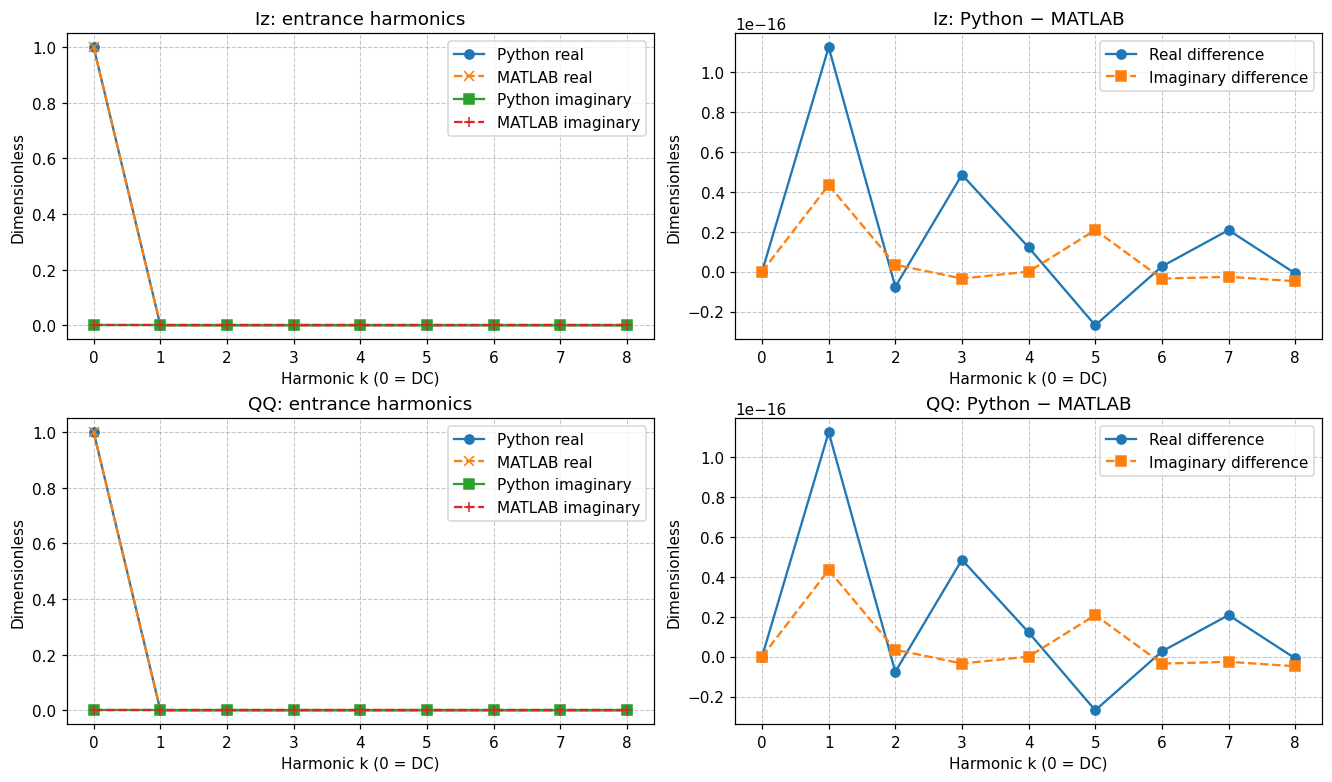

In [6]:
required = ("Iz", "QQ", "IzDC", "QQDC")
if all(name in pairs for name in required):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
    for row, (name, dc_name) in enumerate((("Iz", "IzDC"), ("QQ", "QQDC"))):
        python_values = np.r_[pairs[dc_name][0][0], pairs[name][0][0]]
        matlab_values = np.r_[pairs[dc_name][1][0], pairs[name][1][0]]
        harmonics = np.arange(len(python_values))
        ax = axes[row, 0]
        ax.plot(harmonics, python_values.real, "o-", label="Python real")
        ax.plot(harmonics, matlab_values.real, "x--", label="MATLAB real")
        ax.plot(harmonics, python_values.imag, "s-", label="Python imaginary")
        ax.plot(harmonics, matlab_values.imag, "+--", label="MATLAB imaginary")
        ax.set_title(f"{name}: entrance harmonics")
        ax.legend()
        difference = python_values - matlab_values
        ax = axes[row, 1]
        ax.plot(harmonics, difference.real, "o-", label="Real difference")
        ax.plot(harmonics, difference.imag, "s--", label="Imaginary difference")
        ax.set_title(f"{name}: Python − MATLAB")
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useOffset=False)
        ax.legend()
        for ax in axes[row]:
            ax.set(xticks=harmonics, xlabel="Harmonic k (0 = DC)", ylabel="Dimensionless")
    plt.show()
else:
    print("Harmonic plots unavailable: inspect the numerical summary.")


## 5. Per-harmonic errors over all longitudinal nodes

This table includes harmonic zero and takes the maximum **complex absolute difference** over all nodes. The five remaining state profiles (`IzDC, QQDC, effe, vez, gamaz`) are also covered entry by entry in the main numerical summary.


In [7]:
if all(name in pairs for name in ("Iz", "QQ", "IzDC", "QQDC")):
    current_error = np.r_[
        np.max(np.abs(pairs["IzDC"][0] - pairs["IzDC"][1])),
        np.max(np.abs(pairs["Iz"][0] - pairs["Iz"][1]), axis=0),
    ]
    charge_error = np.r_[
        np.max(np.abs(pairs["QQDC"][0] - pairs["QQDC"][1])),
        np.max(np.abs(pairs["QQ"][0] - pairs["QQ"][1]), axis=0),
    ]
    table = ["| Harmonic | Max Iz error | Max QQ error |", "|---|---|---|"]
    for k in range(len(current_error)):
        table.append(f"| {k} | {current_error[k]:.3e} | {charge_error[k]:.3e} |")
    display(Markdown("\n".join(table)))
else:
    print("Per-harmonic table unavailable: inspect the numerical summary.")


| Harmonic | Max Iz error | Max QQ error |
|---|---|---|
| 0 | 0.000e+00 | 0.000e+00 |
| 1 | 1.205e-16 | 1.205e-16 |
| 2 | 8.345e-18 | 8.345e-18 |
| 3 | 4.870e-17 | 4.870e-17 |
| 4 | 1.214e-17 | 1.214e-17 |
| 5 | 3.400e-17 | 3.400e-17 |
| 6 | 4.337e-18 | 4.337e-18 |
| 7 | 2.098e-17 | 2.098e-17 |
| 8 | 4.888e-18 | 4.888e-18 |

## 6. Final result

A pass establishes agreement for the saved **initialization** case, not space charge, particle trajectories, current updates, or nonlinear convergence. Inspect input choices, dimensions, complex conventions, and normalization before changing any tolerance.


In [8]:
assert all_passed, "Beam-state comparison did not pass. Review the numerical summary."
print("PASS: all 19 calculated quantities, Nt/Ns metadata, and the case label agree.")


PASS: all 19 calculated quantities, Nt/Ns metadata, and the case label agree.
